<a href="https://colab.research.google.com/github/ZidAvwa/PCVK_Ganjil_2026/blob/main/Week7_Thresholding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**D1.1 - Rename the notebook and mount Google Drive**

---

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


**D1.2 - Import the libraries**

---

In [2]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [3]:
IMAGES = '/content/drive/MyDrive/PCVK Semester 5/Images'
KTP_FILE = '/content/drive/MyDrive/PCVK Semester 5/Images/ktp_fulan.jpg'

def read_image(path, flag=cv.IMREAD_COLOR):
    img = cv.imread(path, flag)
    if img is None:
        raise FileNotFoundError('Image not found: ' + path)
    return img

def show_row(images, titles, figsize):
    plt.figure(figsize=figsize)
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        plt.imshow(im, 'gray', vmin=0, vmax=255, interpolation='nearest')
        plt.title(t)
        plt.xticks([]), plt.yticks([])
    plt.show()

**D1.3 - Global Threshold (manual, threshold = 200)**

---

The five global thresholds are written with NumPy only, following the rules in the module:

| Global threshold type | If pixel > thresh | If pixel ≤ thresh |
|---|---|---|
| BINARY | becomes the maximum value | becomes 0 |
| BINARY_INV | becomes 0 | becomes the maximum value |
| TRUNC | becomes thresh | original value is kept |
| TOZERO | original value is kept | becomes 0 |
| TOZERO_INV | becomes 0 | original value is kept |

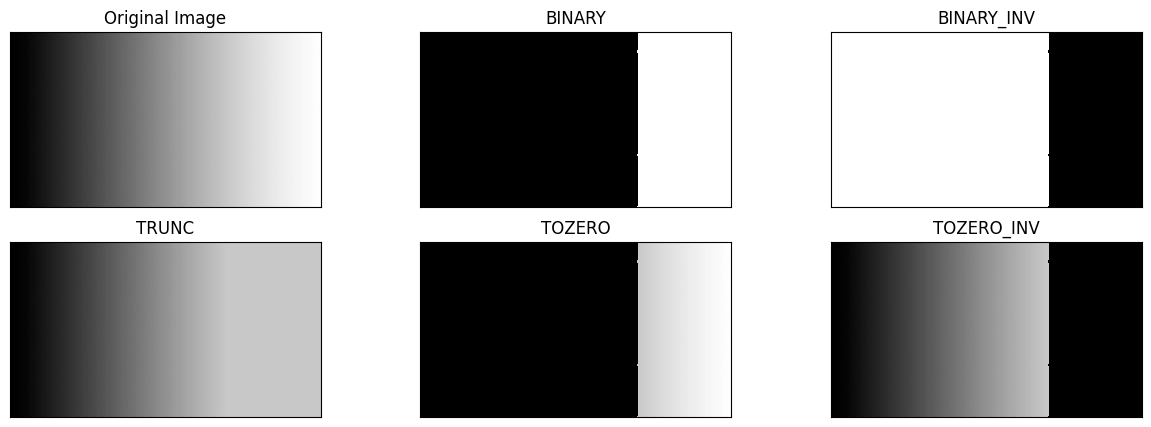

In [4]:
filename = IMAGES + '/gradient.jpg'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)
if img is None:
    img = np.tile(np.linspace(0, 255, 400).astype(np.uint8), (200, 1))
    print('gradient.jpg not found, a synthetic horizontal gradient is used instead')

thresh = 200
maxval = 255

def thresh_binary(src, thresh, maxval):
    return np.where(src > thresh, maxval, 0).astype(np.uint8)

def thresh_binary_inv(src, thresh, maxval):
    return np.where(src > thresh, 0, maxval).astype(np.uint8)

def thresh_trunc(src, thresh):
    return np.where(src > thresh, thresh, src).astype(np.uint8)

def thresh_tozero(src, thresh):
    return np.where(src > thresh, src, 0).astype(np.uint8)

def thresh_tozero_inv(src, thresh):
    return np.where(src > thresh, 0, src).astype(np.uint8)

thresh1 = thresh_binary(img, thresh, maxval)
thresh2 = thresh_binary_inv(img, thresh, maxval)
thresh3 = thresh_trunc(img, thresh)
thresh4 = thresh_tozero(img, thresh)
thresh5 = thresh_tozero_inv(img, thresh)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1), plt.imshow(images[i], 'gray', vmin=0, vmax=255, interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

**Check** - the manual results must be identical to `cv.threshold` (the library is used only for this check).

In [5]:
library_types = [cv.THRESH_BINARY, cv.THRESH_BINARY_INV, cv.THRESH_TRUNC, cv.THRESH_TOZERO, cv.THRESH_TOZERO_INV]
for name, manual, flag in zip(titles[1:], images[1:], library_types):
    ref = cv.threshold(img, thresh, maxval, flag)[1]
    print('%-11s max difference vs cv.threshold: %d' % (name, np.abs(manual.astype(int) - ref.astype(int)).max()))
    assert np.array_equal(manual, ref)

BINARY      max difference vs cv.threshold: 0
BINARY_INV  max difference vs cv.threshold: 0
TRUNC       max difference vs cv.threshold: 0
TOZERO      max difference vs cv.threshold: 0
TOZERO_INV  max difference vs cv.threshold: 0


**D1.4 - Adaptive Threshold (manual): adaptive mean and adaptive Gaussian**

---

In [6]:
def mean_kernel(size):
    return np.full((size, size), 1.0 / (size * size))

def gaussian_kernel(size, sigma):
    ax = np.arange(size) - size // 2
    g = np.exp(-(ax ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return np.outer(g, g)

def local_mean(gray, kernel):
    kh, kw = kernel.shape
    padded = np.pad(gray.astype(np.float64), kh // 2, mode='edge')
    H, W = gray.shape
    out = np.zeros((H, W))
    for i in range(kh):
        for j in range(kw):
            out += kernel[i, j] * padded[i:i + H, j:j + W]
    return out

def adaptive_threshold_manual(gray, kernel, C, maxval=255):
    T = np.round(local_mean(gray, kernel)) - C
    return np.where(gray > T, maxval, 0).astype(np.uint8)

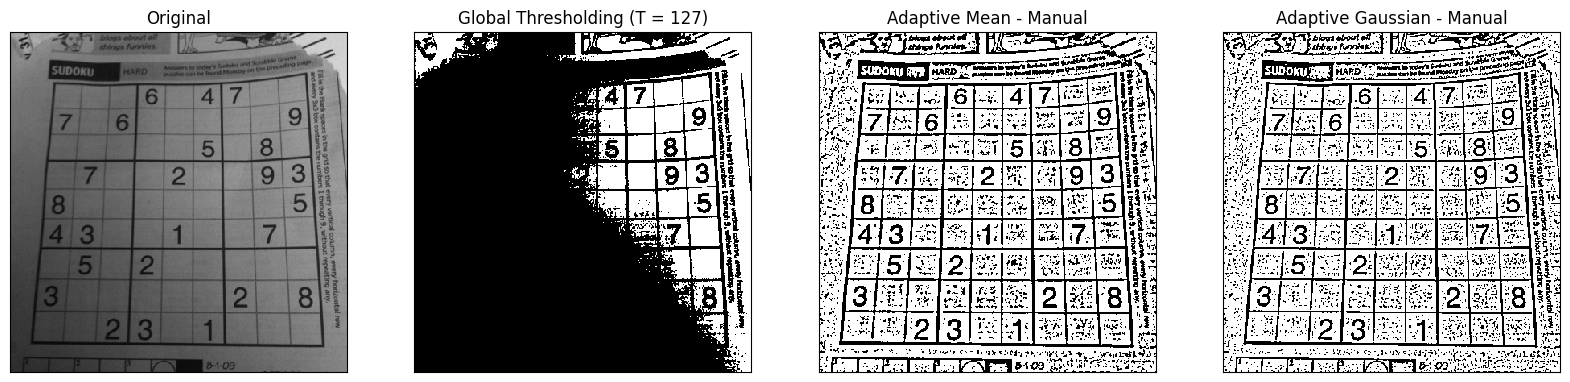

In [7]:
filename = IMAGES + '/sudoku-original.jpg'
gray = read_image(filename, cv.IMREAD_GRAYSCALE)

window = 11
C = 2
sigma = 2

global_manual = thresh_binary(gray, 127, 255)
adaptive_mean = adaptive_threshold_manual(gray, mean_kernel(window), C)
adaptive_gauss = adaptive_threshold_manual(gray, gaussian_kernel(window, sigma), C)

show_row([gray, global_manual, adaptive_mean, adaptive_gauss],
         ['Original', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual'],
         (20, 6))

**Check** - how close are the manual results to OpenCV's `cv.adaptiveThreshold` (library used only for this check)?

In [8]:
ref_mean = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, window, C)
ref_gauss = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, window, C)
print('Adaptive mean:     %.4f%% of the pixels differ from cv.adaptiveThreshold' % ((adaptive_mean != ref_mean).mean() * 100))
print('Adaptive Gaussian: %.4f%% of the pixels differ from cv.adaptiveThreshold' % ((adaptive_gauss != ref_gauss).mean() * 100))

Adaptive mean:     0.0000% of the pixels differ from cv.adaptiveThreshold
Adaptive Gaussian: 0.0000% of the pixels differ from cv.adaptiveThreshold


For an 11 x 11 window OpenCV uses `sigma = 0.3 * ((11 - 1) * 0.5 - 1) + 0.8 = 2`, which is why the module asks for `sigma = 2`.

**D1.5 - Otsu Thresholding (manual)**

---

In [9]:
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    intensity_arr = np.arange(256)
    final_thresh = -1
    final_value = -1
    for t in range(0, 255):
        pcb = np.sum(his[:t + 1])
        pcf = np.sum(his[t + 1:])
        if pcb == 0 or pcf == 0:
            continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t + 1] * his[:t + 1]) / float(pcb)
        muf = np.sum(intensity_arr[t + 1:] * his[t + 1:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = np.where(gray > final_thresh, 255, 0).astype(np.uint8)
    return final_img, final_thresh

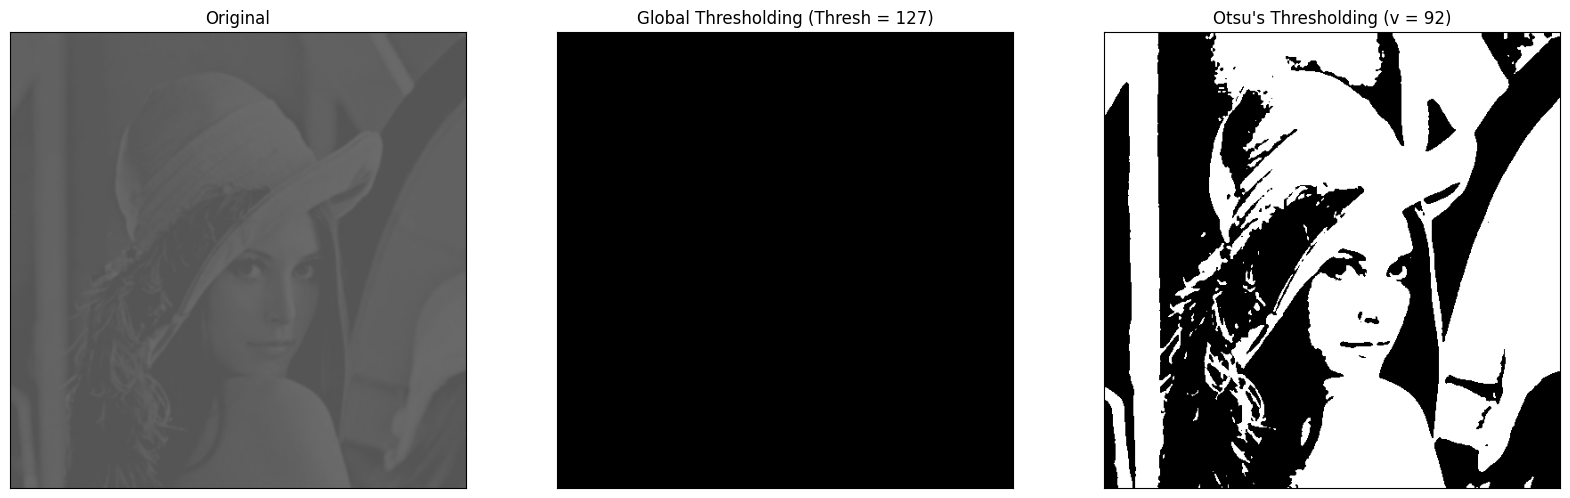

In [10]:
filename = IMAGES + '/lena_gs_lc2.jpg'
img = read_image(filename, cv.IMREAD_GRAYSCALE)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = "Otsu's Thresholding (v = " + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Original', 'Global Thresholding (Thresh = ' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i + 1), plt.imshow(citra3[i], 'gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

**Comparison with the library** (`cv.THRESH_OTSU`, used only to compare)

In [11]:
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
print('Manual Otsu threshold  :', otsu_thresh)
print('Library Otsu threshold :', int(ret2))
print('Pixels that differ between the two results: %.4f%%' % ((otsu_biner != th2).mean() * 100))

Manual Otsu threshold  : 92
Library Otsu threshold : 92
Pixels that differ between the two results: 0.0000%


**Question:** why is the Binary Thresholding result completely black? Explain it with the histogram, and give a threshold at which the Lena image is still visible.

/tmp/ipykernel_1880/3699755102.py:2: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(blur.ravel(), 256, [0, 256], color='gray')


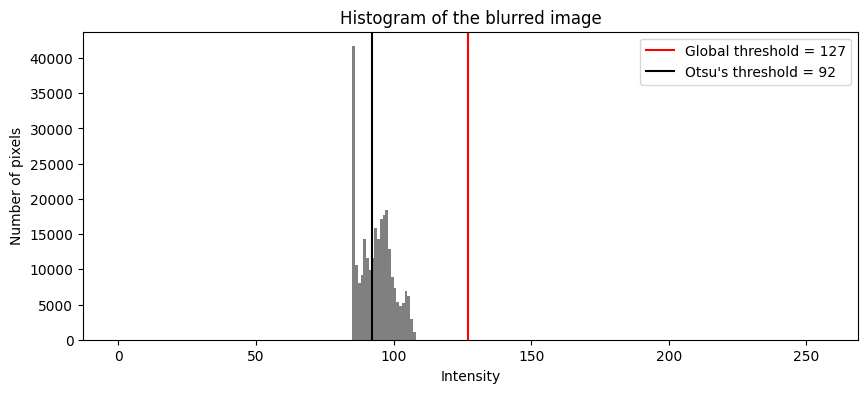

Minimum intensity            : 85
Maximum intensity            : 108
Pixels with intensity > 127  : 0 of 262144


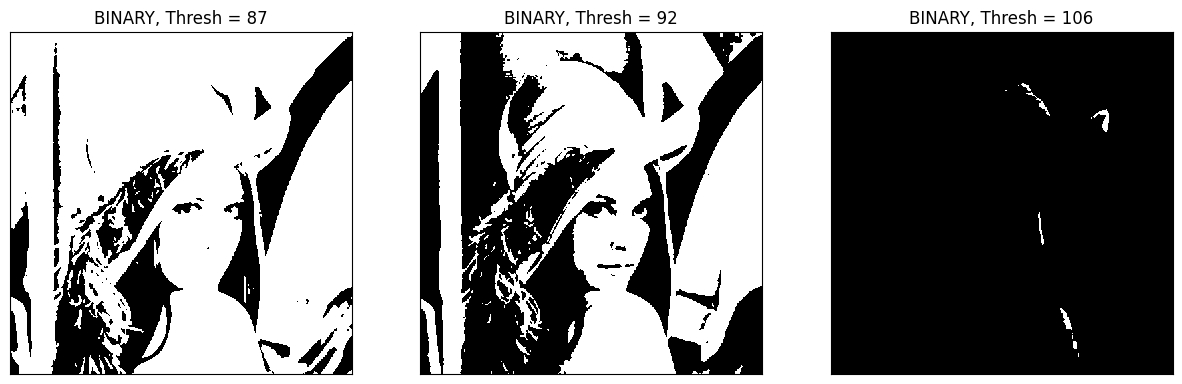

In [12]:
plt.figure(figsize=(10, 4))
plt.hist(blur.ravel(), 256, [0, 256], color='gray')
plt.axvline(127, color='red', label='Global threshold = 127')
plt.axvline(otsu_thresh, color='black', label="Otsu's threshold = " + str(otsu_thresh))
plt.title('Histogram of the blurred image')
plt.xlabel('Intensity')
plt.ylabel('Number of pixels')
plt.legend()
plt.show()

print('Minimum intensity            :', blur.min())
print('Maximum intensity            :', blur.max())
print('Pixels with intensity > 127  : %d of %d' % ((blur > 127).sum(), blur.size))

candidates = [int(blur.min()) + 2, otsu_thresh, int(blur.max()) - 2]
show_row([thresh_binary(blur, t, 255) for t in candidates],
         ['BINARY, Thresh = %d' % t for t in candidates], (15, 5))

**Answer**

- `lena_gs_lc2.jpg` is a low-contrast image: all its intensities lie in a narrow band of roughly 85 to 108 (check the minimum and maximum printed above). The BINARY rule turns a pixel white only if `pixel > thresh`. Because every pixel is below 127, the condition is false for all pixels, so every pixel becomes 0 and the result is completely black.
- In the histogram the whole mass of pixels lies to the left of the red line at 127, so the threshold does not split it into two groups at all.
- For the image to stay visible, the threshold must fall **inside** the occupied intensity range, between the minimum and the maximum, ideally in the valley between the two groups of the histogram. Otsu finds this automatically and gives about 92 for this image (see the printed value); thresholds in the 85 to 108 band, such as the ones in the last figure, also keep Lena visible.

**B.** The same comparison on your own ID card image (`KTP_FILE`): Otsu's threshold versus the ordinary global threshold of 127.

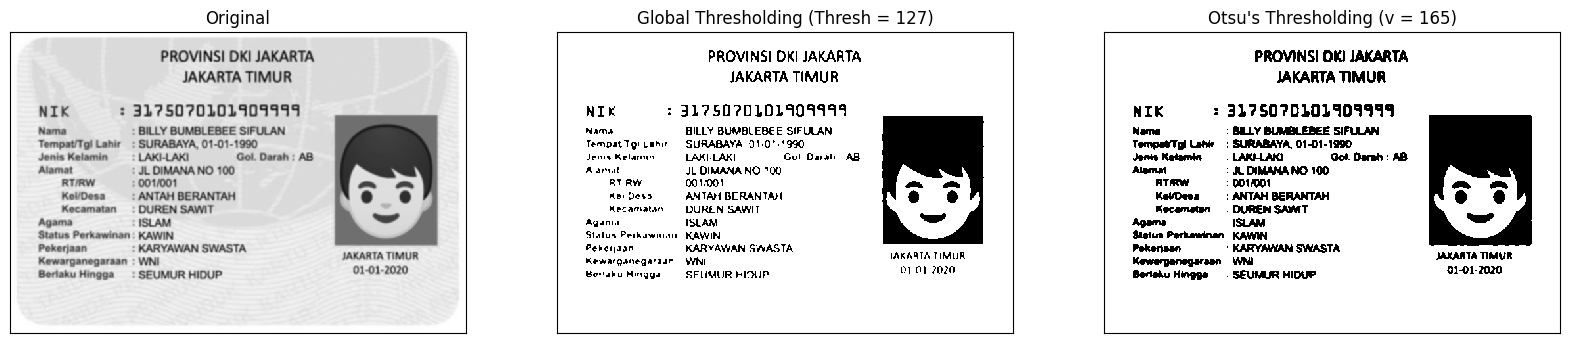

/tmp/ipykernel_1880/140228401.py:11: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(ktp_blur.ravel(), 256, [0, 256], color='gray')


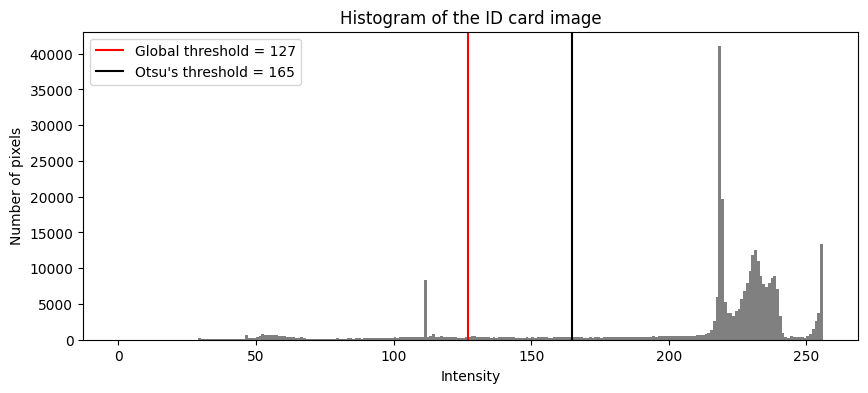

In [13]:
ktp = read_image(KTP_FILE, cv.IMREAD_GRAYSCALE)
ktp_blur = cv.GaussianBlur(ktp, (5, 5), 0)
ktp_otsu, ktp_t = otsu(ktp_blur)
ktp_global = thresh_binary(ktp_blur, 127, 255)

show_row([ktp_blur, ktp_global, ktp_otsu],
         ['Original', 'Global Thresholding (Thresh = 127)', "Otsu's Thresholding (v = " + str(ktp_t) + ")"],
         (20, 6))

plt.figure(figsize=(10, 4))
plt.hist(ktp_blur.ravel(), 256, [0, 256], color='gray')
plt.axvline(127, color='red', label='Global threshold = 127')
plt.axvline(ktp_t, color='black', label="Otsu's threshold = " + str(ktp_t))
plt.title('Histogram of the ID card image')
plt.xlabel('Intensity')
plt.ylabel('Number of pixels')
plt.legend()
plt.show()

**Comparison**

- **Where the threshold falls.** Otsu's threshold is 165, higher than the fixed 127. The histogram has a small group of dark pixels (text and photo, roughly 30-110) and one very tall group of bright pixels (card background, roughly 215-255), with an almost empty valley between them. Otsu places its line in this valley, while 127 sits closer to the dark group.
- **Text and photo.** Both results keep the text and the photo readable, because the gap between the two groups is wide. With 127 the small grey strokes (the labels *Nama*, *Tempat/Tgl Lahir*, *Jenis Kelamin*, *Alamat*) come out thin and slightly broken. With 165 the strokes are fuller and more continuous, so small text is easier to read. The photo becomes a black block with a white face in both results.
- **Background.** The light-blue guilloche pattern is brighter than both thresholds (about 215-240), so in both results the card background becomes clean white without noise.
- **Conclusion.** On this card the two methods are close, since the contrast is high. Otsu is slightly better because it chose the threshold from the histogram instead of using a number that was fixed in advance. With a card photographed in darker light the fixed 127 would fail, while Otsu would still follow the histogram (as it did for the Lena image).

**D1.6 - Region-Based Segmentation on skimage `data.coins()`**

---

**A.** Region growing implemented by hand with a queue (`deque`). Starting from a seed pixel, a 4-connected neighbour joins the region when its intensity differs from the seed intensity by at most `T`. Three seeds are used (inside a coin, in the background, exactly on the edge of a coin), each run with `T = 5, 20, 60`, and the 9 results are shown as a 3 x 3 grid (seed x T).

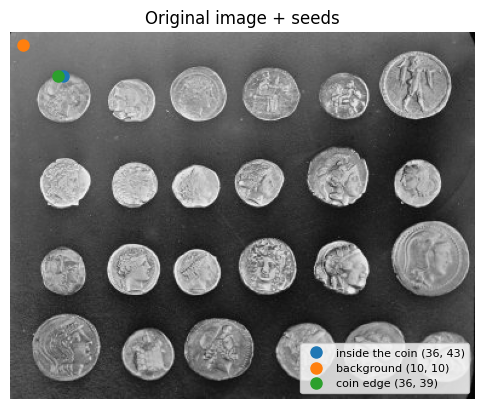

In [14]:
gray = data.coins()

def region_growing(gray, seed, tol):
    h, w = gray.shape
    seed_value = int(gray[seed])
    mask = np.zeros((h, w), dtype=bool)
    mask[seed] = True
    queue = deque([seed])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not mask[nr, nc] and abs(int(gray[nr, nc]) - seed_value) <= tol:
                mask[nr, nc] = True
                queue.append((nr, nc))
    return mask

def overlay(gray, mask, seed):
    rgb = np.stack([gray] * 3, axis=-1).copy()
    rgb[mask] = (255, 0, 0)
    r, c = seed
    rgb[max(r - 2, 0):r + 3, max(c - 2, 0):c + 3] = (0, 255, 255)
    return rgb

seeds = [('inside the coin', (36, 43)), ('background', (10, 10)), ('coin edge', (36, 39))]
tolerances = [5, 20, 60]

plt.figure(figsize=(6, 5))
plt.imshow(gray, 'gray')
for name, (r, c) in seeds:
    plt.plot(c, r, 'o', markersize=8, label=name + ' (%d, %d)' % (r, c))
plt.legend(loc='lower right', fontsize=8)
plt.title('Original image + seeds')
plt.axis('off')
plt.show()

Seed (row, col): (36, 43) | intensity: 159 | inside the coin
    Tolerance  5: 21 pixels
    Tolerance 20: 919 pixels
    Tolerance 60: 15253 pixels
Seed (row, col): (10, 10) | intensity: 127 | background
    Tolerance  5: 2462 pixels
    Tolerance 20: 7762 pixels
    Tolerance 60: 42117 pixels
Seed (row, col): (36, 39) | intensity: 132 | coin edge
    Tolerance  5: 1 pixels
    Tolerance 20: 27 pixels
    Tolerance 60: 40219 pixels


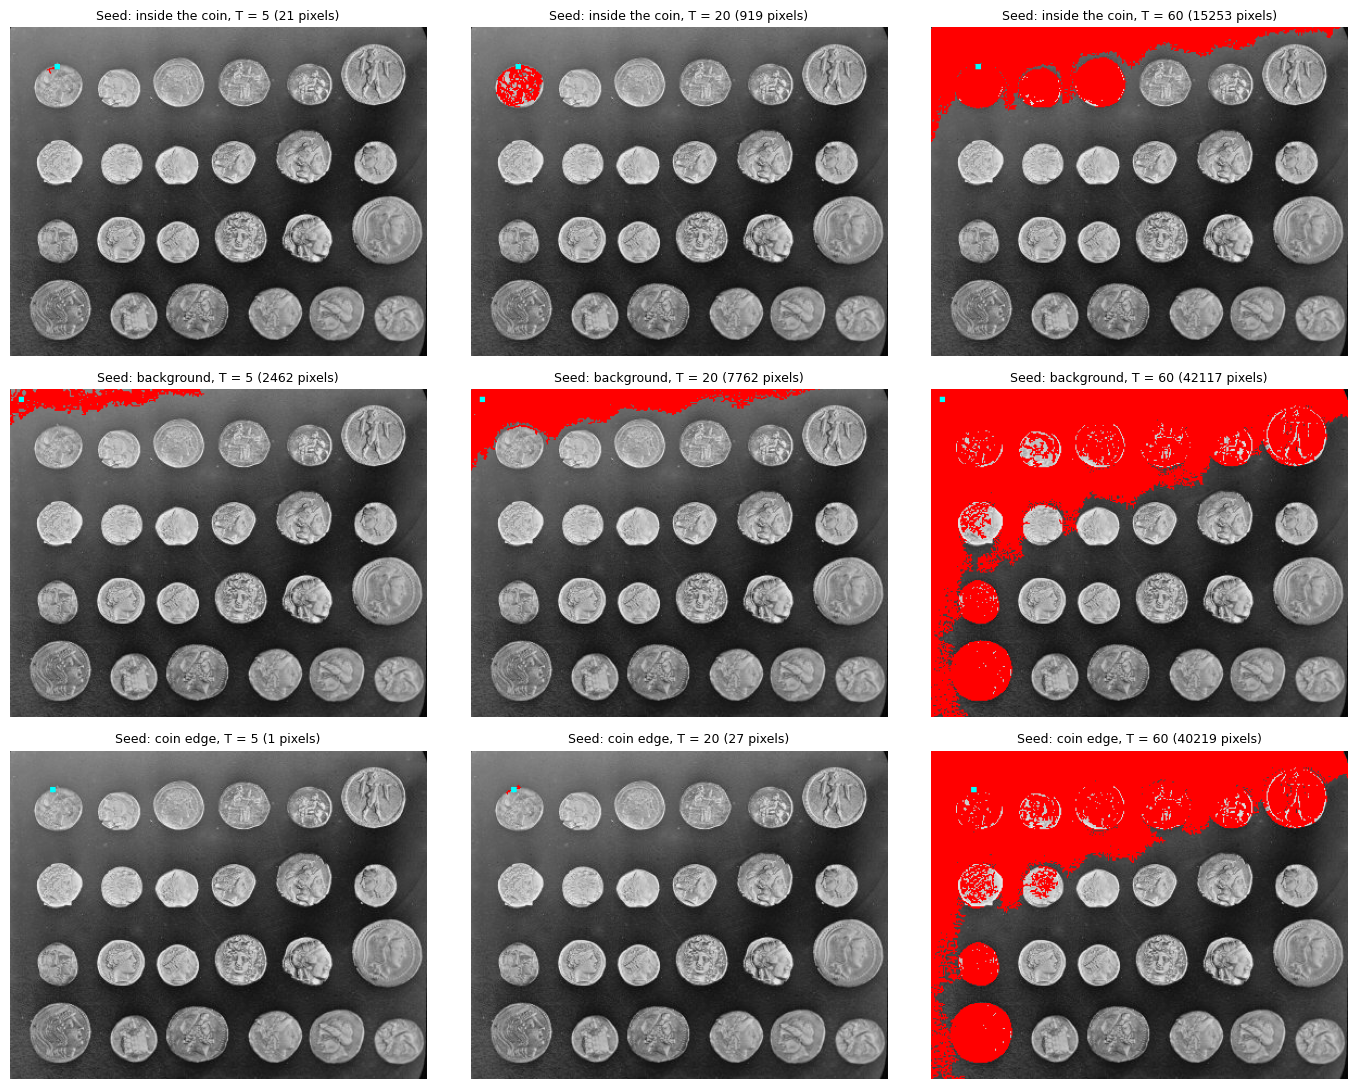

In [15]:
manual_masks = {}
for name, seed in seeds:
    print('Seed (row, col): %s | intensity: %d | %s' % (seed, gray[seed], name))
    for T in tolerances:
        manual_masks[(seed, T)] = region_growing(gray, seed, T)
        print('    Tolerance %2d: %d pixels' % (T, manual_masks[(seed, T)].sum()))

plt.figure(figsize=(14, 11))
for i, (name, seed) in enumerate(seeds):
    for j, T in enumerate(tolerances):
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(overlay(gray, manual_masks[(seed, T)], seed))
        plt.title('Seed: %s, T = %d (%d pixels)' % (name, T, manual_masks[(seed, T)].sum()), fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

**Reading the grid** (pixel counts are the ones printed above; `data.coins()` is a fixed image, so they are reproducible)

- *Inside the coin* (intensity 159): `T = 5` gives only a small patch of 21 pixels around the seed, `T = 20` covers most of the coin (919 pixels), and `T = 60` leaks out of the coin into the background and the neighbouring coins (15,253 pixels).
- *Background* (intensity 127): the background has a smooth intensity gradient, so the region keeps growing as `T` increases (2,462, 7,762 and then 42,117 pixels), and at `T = 60` it starts to swallow the coins.
- *Coin edge* (intensity 132): the seed value lies between the coin and the background, so the result is unstable. `T = 5` gives a single pixel (the seed itself), `T = 20` a tiny region of 27 pixels, and `T = 60` suddenly floods about a third of the image (40,219 pixels). This shows how sensitive region growing is to the seed position and to the threshold.

**B.** The same segmentation with the ready-made `skimage.segmentation.flood()`. It returns the mask of all pixels connected to the seed whose intensity is within the tolerance of the seed intensity. With `connectivity=1` (4 neighbours) it must agree with the manual version.

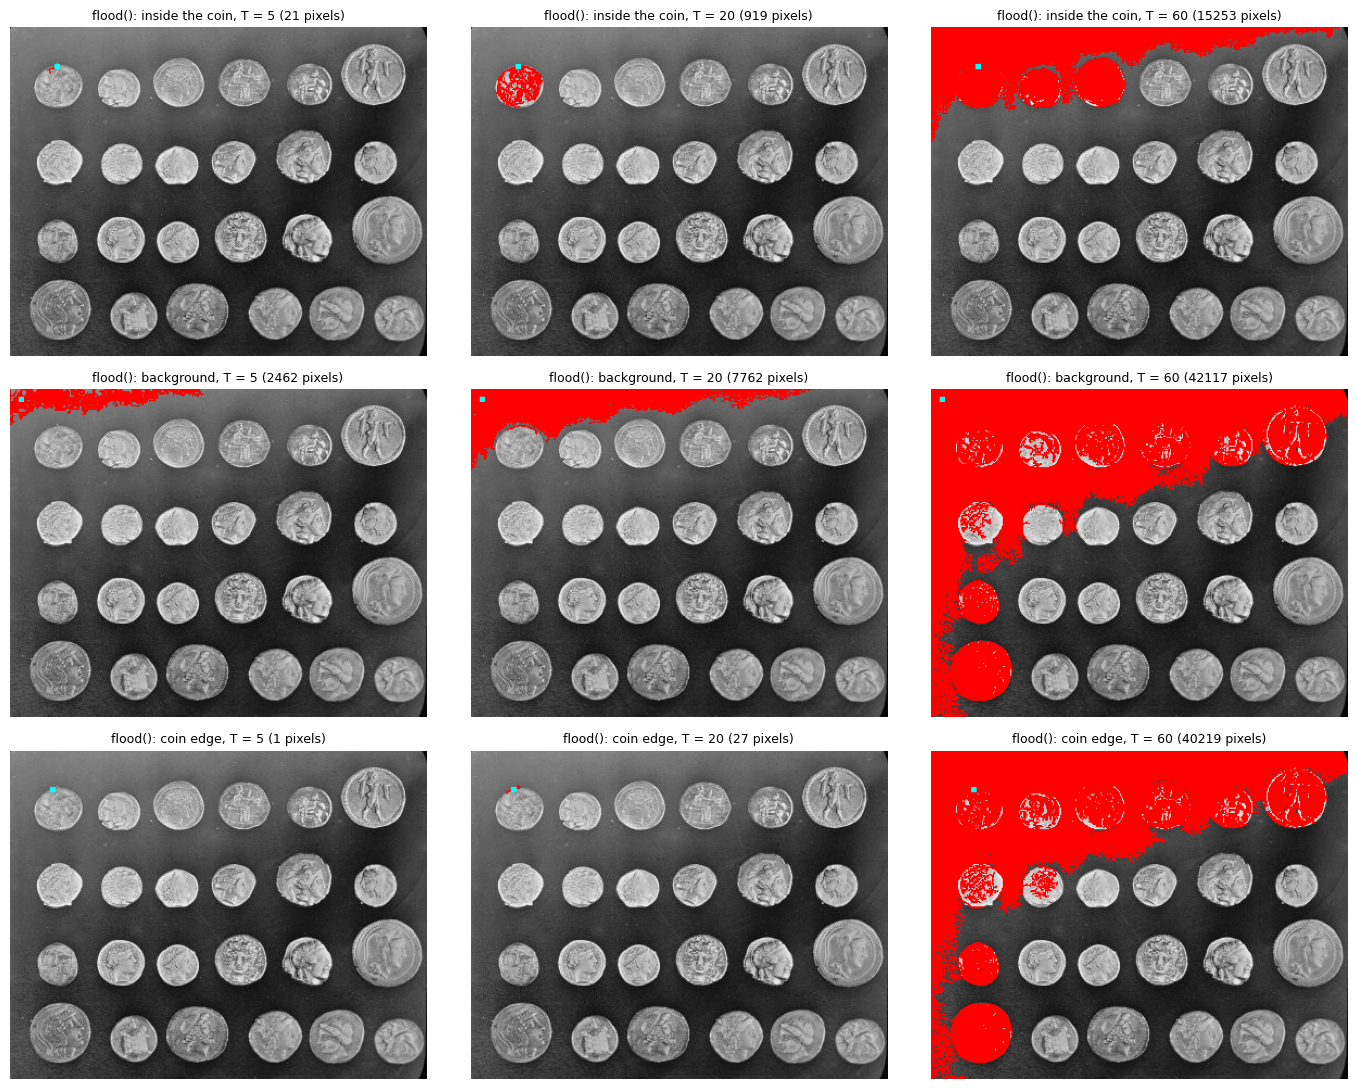

inside the coin  T =  5 | manual     21 pixels | flood     21 pixels | identical: True
inside the coin  T = 20 | manual    919 pixels | flood    919 pixels | identical: True
inside the coin  T = 60 | manual  15253 pixels | flood  15253 pixels | identical: True
background       T =  5 | manual   2462 pixels | flood   2462 pixels | identical: True
background       T = 20 | manual   7762 pixels | flood   7762 pixels | identical: True
background       T = 60 | manual  42117 pixels | flood  42117 pixels | identical: True
coin edge        T =  5 | manual      1 pixels | flood      1 pixels | identical: True
coin edge        T = 20 | manual     27 pixels | flood     27 pixels | identical: True
coin edge        T = 60 | manual  40219 pixels | flood  40219 pixels | identical: True


In [16]:
flood_masks = {}
for name, seed in seeds:
    for T in tolerances:
        flood_masks[(seed, T)] = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

plt.figure(figsize=(14, 11))
for i, (name, seed) in enumerate(seeds):
    for j, T in enumerate(tolerances):
        plt.subplot(3, 3, i * 3 + j + 1)
        plt.imshow(overlay(gray, flood_masks[(seed, T)], seed))
        plt.title('flood(): %s, T = %d (%d pixels)' % (name, T, flood_masks[(seed, T)].sum()), fontsize=9)
        plt.axis('off')
plt.tight_layout()
plt.show()

for name, seed in seeds:
    for T in tolerances:
        same = np.array_equal(manual_masks[(seed, T)], flood_masks[(seed, T)])
        print('%-16s T = %2d | manual %6d pixels | flood %6d pixels | identical: %s'
              % (name, T, manual_masks[(seed, T)].sum(), flood_masks[(seed, T)].sum(), same))

**D1.7 - Color Segmentation: show only the blue color of the ID card**

---

K-Means (K = 8) first reduces the card image to 8 colours. The result is converted to HSV, and only the pixels in the blue range of the card background are kept: `85 <= H <= 130`, `S >= 25`, `V >= 40` (OpenCV hue runs from 0 to 179). Every other pixel is set to black.

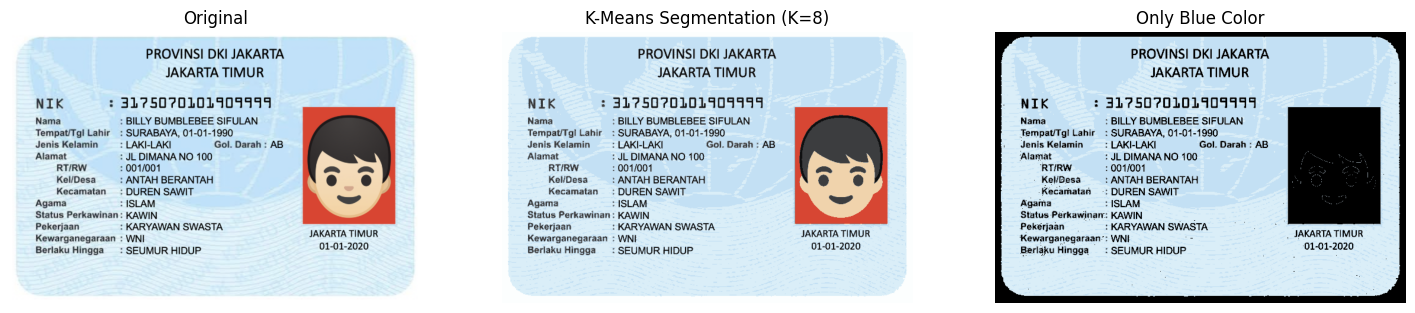

In [17]:
from sklearn.cluster import KMeans

ktp_rgb = cv.cvtColor(read_image(KTP_FILE), cv.COLOR_BGR2RGB)

Z = np.float32(ktp_rgb.reshape((-1, 3)))
k = 8
kmeans = KMeans(n_clusters=k, random_state=42, n_init=3)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
segmented = centers[labels.flatten()].reshape(ktp_rgb.shape)

hsv = cv.cvtColor(segmented, cv.COLOR_RGB2HSV)
H, S, V = hsv[:, :, 0], hsv[:, :, 1], hsv[:, :, 2]
blue_group = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

only_blue = np.zeros_like(segmented)
only_blue[blue_group] = segmented[blue_group]

plt.figure(figsize=(18, 5))
for i, (im, t) in enumerate(zip([ktp_rgb, segmented, only_blue],
                                ['Original', 'K-Means Segmentation (K=8)', 'Only Blue Color'])):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im)
    plt.title(t)
    plt.axis('off')
plt.show()

In [18]:
center_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV).reshape(-1, 3)
sizes = np.bincount(labels, minlength=k)
table = pd.DataFrame({'cluster': range(k),
                      'RGB center': [tuple(int(v) for v in c) for c in centers],
                      'H': center_hsv[:, 0], 'S': center_hsv[:, 1], 'V': center_hsv[:, 2],
                      'pixels (%)': np.round(sizes / sizes.sum() * 100, 1),
                      'kept as blue': [(85 <= h <= 130) and (s >= 25) and (v >= 40) for h, s, v in center_hsv]})
print(table.to_string(index=False))
print('\nPixels kept as blue: %.1f%%' % (len(blue_group[0]) / (H.shape[0] * H.shape[1]) * 100))

 cluster      RGB center   H   S   V  pixels (%)  kept as blue
       0    (60, 61, 63) 110  12  63         5.3         False
       1 (218, 238, 248) 100  31 248        38.8          True
       2   (215, 70, 51)   3 195 215         3.4         False
       3    (15, 16, 17) 105  30  17         2.7         False
       4 (138, 149, 157) 103  31 157         2.9          True
       5 (240, 211, 172)  17  72 240         2.8         False
       6 (252, 254, 254)  90   2 254         7.9         False
       7 (195, 224, 244) 102  51 244        36.1          True

Pixels kept as blue: 77.8%


**D2 - Group Task: OCR of the ID card (original vs Otsu vs Adaptive segmentation)**

---

##**GROUP**

**Eiyu Azizuly Efendi** / 244107020181 \
**Zid’Avwa Al Bari’i** / 244107020083


In [19]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


**Step 1 - Prepare the three images.**

Otsu threshold: 151


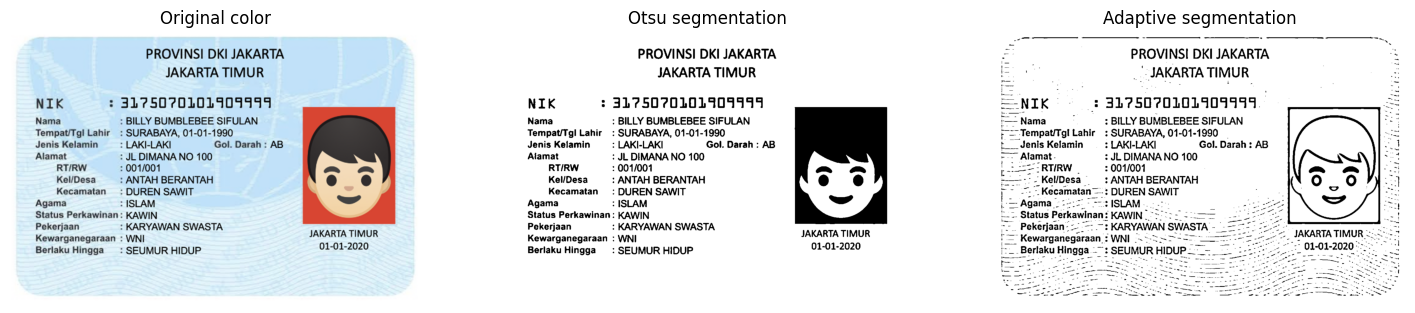

In [20]:
import re
import difflib
import pytesseract
from pytesseract import Output

LANG = 'ind'
CONFIG = '--psm 6'
CONF_MIN = 60
WIDTH = 1400

ktp_bgr = read_image(KTP_FILE)
scale = WIDTH / ktp_bgr.shape[1]
ktp_bgr = cv.resize(ktp_bgr, None, fx=scale, fy=scale, interpolation=cv.INTER_CUBIC)
ktp_gray = cv.cvtColor(ktp_bgr, cv.COLOR_BGR2GRAY)
otsu_value, ktp_otsu_img = cv.threshold(ktp_gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
ktp_adaptive_img = cv.adaptiveThreshold(ktp_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 31, 10)

names = ['Original color', 'Otsu segmentation', 'Adaptive segmentation']
inputs = [ktp_bgr, ktp_otsu_img, ktp_adaptive_img]
print('Otsu threshold:', int(otsu_value))

plt.figure(figsize=(18, 5))
for i, (im, t) in enumerate(zip(inputs, names)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB) if im.ndim == 3 else im, 'gray')
    plt.title(t)
    plt.axis('off')
plt.show()

**Step 2 - Read the text**

In [21]:
def run_ocr(img):
    rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB) if img.ndim == 3 else img
    text = pytesseract.image_to_string(rgb, lang=LANG, config=CONFIG)
    info = pytesseract.image_to_data(rgb, lang=LANG, config=CONFIG, output_type=Output.DICT)
    return text, info

results = [run_ocr(im) for im in inputs]
for name, (text, info) in zip(names, results):
    print('=== %s ===' % name)
    print(text.strip())
    print()

=== Original color ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3275070101909447
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Alamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH t 4

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan: KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga — : SEUMUR HIDUP 01-01-2020

=== Otsu segmentation ===
PROVINSI DKI JAKARTA
JAKARTA TIMUR

NIK : 3275070101409147
Nama : BILLY BUMBLEBEE SIFULAN
Tempat/Tgl Lahir : SURABAYA, 01-01-1990
Jenis Kelamin : LAKI-LAKI Gol. Darah : AB
Atamat : JL DIMANA NO 100

RT/RW : 001/001

Kel/Desa : ANTAH BERANTAH

Kecamatan : DUREN SAWIT
Agama : ISLAM
Status Perkawinan : KAWIN
Pekerjaan : KARYAWAN SWASTA
Kewarganegaraan : WNI JAKARTA TIMUR
Berlaku Hingga: SEUMUR HIDUP 01-01-2020

=== Adaptive segmentation ===
- PROVINSI DKI JAKARTA 1
Po JAKARTA TIMUR 5
—. Pos “. 25 | | 2 ae
—NIK - 3: 31?507010110919

**Step 3 - Show the recognised text areas** with `pytesseract.image_to_data()`

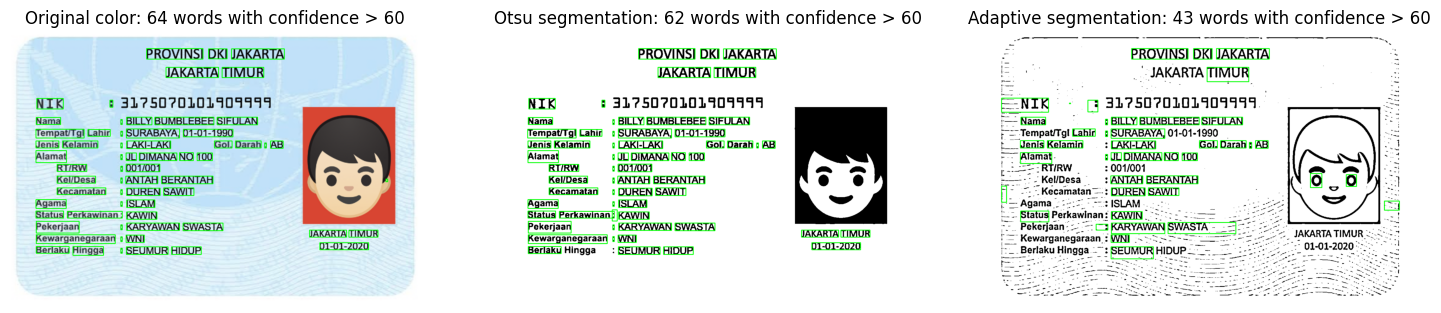

In [22]:
def draw_boxes(img, info, conf_min):
    canvas = cv.cvtColor(img, cv.COLOR_GRAY2BGR) if img.ndim == 2 else img.copy()
    count = 0
    for i in range(len(info['text'])):
        if info['text'][i].strip() and float(info['conf'][i]) > conf_min:
            x, y, w, h = info['left'][i], info['top'][i], info['width'][i], info['height'][i]
            cv.rectangle(canvas, (x, y), (x + w, y + h), (0, 255, 0), 2)
            count += 1
    return canvas, count

plt.figure(figsize=(18, 6))
for i, (name, im, (text, info)) in enumerate(zip(names, inputs, results)):
    boxed, count = draw_boxes(im, info, CONF_MIN)
    plt.subplot(1, 3, i + 1)
    plt.imshow(cv.cvtColor(boxed, cv.COLOR_BGR2RGB))
    plt.title('%s: %d words with confidence > %d' % (name, count, CONF_MIN))
    plt.axis('off')
plt.show()

**Step 4 - Compare with the real text.**

In [23]:
reference = ['PROVINSI', 'NIK', 'Nama', 'Alamat', 'Agama', 'Pekerjaan',
             'Kewarganegaraan', 'Berlaku Hingga', 'Jenis Kelamin', 'Status Perkawinan']

def clean(s):
    return re.sub(r'[^0-9a-z ]', '', s.lower())

def ocr_tokens(text):
    return [clean(w) for w in text.split() if clean(w)]

def is_match(ref, text):
    r = ' '.join(clean(ref).split())
    t = ocr_tokens(text)
    if ' ' in r:
        return r in ' '.join(t)
    return r in t

def closest(ref, text):
    if is_match(ref, text):
        return ref
    r = ' '.join(clean(ref).split())
    t = ocr_tokens(text)
    n = len(r.split())
    pool = t if n == 1 else [' '.join(t[i:i + n]) for i in range(len(t))]
    found = difflib.get_close_matches(r, pool, n=1, cutoff=0.6)
    return found[0] if found else '(not read)'

texts = [text for text, info in results]
rows = []
for i, ref in enumerate(reference, 1):
    rows.append([i, ref] + [closest(ref, t) for t in texts])
comparison = pd.DataFrame(rows, columns=['No.', 'Actual text', 'OCR color image', 'OCR Otsu', 'OCR Adaptive'])
print(comparison.to_string(index=False))

 No.       Actual text   OCR color image          OCR Otsu      OCR Adaptive
   1          PROVINSI          PROVINSI          PROVINSI          PROVINSI
   2               NIK               NIK               NIK               NIK
   3              Nama              Nama              Nama              Nama
   4            Alamat            Alamat            atamat            Alamat
   5             Agama             Agama             Agama             Agama
   6         Pekerjaan         Pekerjaan         Pekerjaan         Pekerjaan
   7   Kewarganegaraan   Kewarganegaraan   Kewarganegaraan   Kewarganegaraan
   8    Berlaku Hingga    Berlaku Hingga    Berlaku Hingga    Berlaku Hingga
   9     Jenis Kelamin     Jenis Kelamin     Jenis Kelamin     Jenis Kelamin
  10 Status Perkawinan Status Perkawinan Status Perkawinan Status Perkawinan


**Step 5 - Match percentage and average confidence.** `Match (%) = items read exactly / 10 x 100%`. The average confidence is the mean confidence that Tesseract reports for all recognised words in the image (words with text and a confidence of at least 0).

In [24]:
def mean_conf(info):
    values = [float(c) for c, t in zip(info['conf'], info['text']) if t.strip() and float(c) >= 0]
    return sum(values) / len(values) if values else 0.0

summary = []
for name, (text, info) in zip(names, results):
    exact = sum(is_match(r, text) for r in reference)
    summary.append({'OCR input image': name,
                    'Items read exactly': exact,
                    'Match (%)': exact / len(reference) * 100,
                    'Average confidence': round(mean_conf(info), 1)})
print(pd.DataFrame(summary).to_string(index=False))

      OCR input image  Items read exactly  Match (%)  Average confidence
       Original color                  10      100.0                88.6
    Otsu segmentation                   9       90.0                89.8
Adaptive segmentation                  10      100.0                40.4


**Analysis questions**

1. **Which input image gives the most accurate reading? Show the evidence from the table.**
   *(Compare the "Match (%)" column of the three rows.)*
2. **Name at least two reading mistakes**, such as swapped letters, a wrong digit, or text that is not read at all.
   *(Take them from the `OCR` columns of the comparison table, for example an item that shows a different word or `(not read)`.)*
3. **Does segmentation always improve OCR accuracy?**
   *(Compare the colour row with the Otsu and Adaptive rows: if a thresholded image has a lower match than the colour image, segmentation hurt; explain why, for example text strokes lost by a bad threshold or noise left in the background.)*
4. **How do the colour or pattern of the background affect the reading?**
   *(Look at the guilloche pattern and the coloured background of the card in the three images, and at the words that were lost or misread near them.)*
5. **Does the method with the highest average confidence also have the highest match?**
   *(Compare the "Average confidence" and "Match (%)" columns: the confidence is Tesseract's own estimate and does not have to agree with the real accuracy.)*

**Answers**

| No. | Actual text | OCR colour image | OCR Otsu | OCR Adaptive |
|---|---|---|---|---|
| 1 | PROVINSI | PROVINSI | PROVINSI | PROVINSI |
| 2 | NIK | NIK | NIK | NIK |
| 3 | Nama | Nama | Nama | Nama |
| 4 | Alamat | Alamat | atamat | Alamat |
| 5 | Agama | Agama | Agama | Agama |
| 6 | Pekerjaan | Pekerjaan | Pekerjaan | Pekerjaan |
| 7 | Kewarganegaraan | Kewarganegaraan | Kewarganegaraan | Kewarganegaraan |
| 8 | Berlaku Hingga | Berlaku Hingga | Berlaku Hingga | Berlaku Hingga |
| 9 | Jenis Kelamin | Jenis Kelamin | Jenis Kelamin | Jenis Kelamin |
| 10 | Status Perkawinan | Status Perkawinan | Status Perkawinan | Status Perkawinan |

**Answers**

1. **Colour and Adaptive are tied at 100 % (10/10)**, and Otsu is lower at 90 % (9/10). I'd call colour the most reliable, because the Adaptive output also contains a lot of noise text.

2. **Reading mistakes:**
   - Otsu read "Alamat" as "atamat".
   - The NIK digits were wrong in all three images. The real number is `3175070101909999`, but the colour image gave `3275070101909447`, Otsu gave `3275070101409147`, and Adaptive gave `31?5070101109199`.

3. **No.** Otsu (90 %) was worse than the colour image (100 %), because its thick strokes damaged a small word. Adaptive only tied with colour and added noise. The colour image was already easy to read, so segmentation had little to improve.

4. **The light-blue pattern is brighter than the Otsu threshold**, so Otsu turns the background clean white. Adaptive uses a local threshold, so it turns the faint pattern lines into black specks, and Tesseract reads them as junk characters.

5. **No.** Otsu has the highest confidence (89.8) but the lowest match (90 %). Adaptive has the lowest confidence (40.4) but a 100 % match. Confidence is averaged over all recognised words, including the junk words, and it doesn't measure whether a word is correct.